In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
# Load the Superstore dataset

file_path = "../data/sample_-_superstore.xls"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Dataset loaded successfully!
Rows: 10194
Columns: 21


In [7]:
# Display the first 5 rows

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/23,1/7/23,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/23,1/8/23,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/23,1/8/23,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/23,1/8/23,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/23,1/12/23,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [8]:
# Display column names

print("Columns in the dataset:")
print(df.columns.tolist())

Columns in the dataset:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [9]:
# Check the data types of our columns

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  str    
 6   Customer Name   10194 non-null  str    
 7   Segment         10194 non-null  str    
 8   Country/Region  10194 non-null  str    
 9   City            10194 non-null  str    
 10  State/Province  10194 non-null  str    
 11  Postal Code     10194 non-null  str    
 12  Region          10194 non-null  str    
 13  Product ID      10194 non-null  str    
 14  Category        10194 non-null  str    
 15  Sub-Category    10194 non-null  str    
 16  Product Name    10194 non-null  str    
 17  Sales           10194 non-null  float64
 1

In [10]:
# Check for missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

Missing values in each column:
Series([], dtype: int64)


In [11]:
# Convert date columns to datetime format

df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print("Date columns converted successfully!")
print(df[["Order Date", "Ship Date"]].dtypes)

Date columns converted successfully!
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


C:\Users\srinu\AppData\Local\Temp\ipykernel_23424\99971616.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Order Date"] = pd.to_datetime(df["Order Date"])
C:\Users\srinu\AppData\Local\Temp\ipykernel_23424\99971616.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Ship Date"] = pd.to_datetime(df["Ship Date"])


In [12]:
# Convert date columns to datetime format

df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

print("Date columns converted successfully!")
print(df[["Order Date", "Ship Date"]].dtypes)

Date columns converted successfully!
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [13]:
# Create time-based columns for visualization

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%b")
df["Year-Month"] = df["Order Date"].dt.to_period("M")

print("Time columns created successfully!")

Time columns created successfully!


In [14]:
df[["Order Date", "Year", "Month", "Month Name", "Year-Month"]].head()

,Order Date,Year,Month,Month Name,Year-Month
0,2023-01-03,2023,1,Jan,2023-01
1,2023-01-04,2023,1,Jan,2023-01
2,2023-01-04,2023,1,Jan,2023-01
3,2023-01-04,2023,1,Jan,2023-01
4,2023-01-05,2023,1,Jan,2023-01


In [11]:
# Calculate monthly sales

monthly_sales = (
    df.groupby("Year-Month")["Sales"]
    .sum()
    .reset_index()
)

monthly_sales["Year-Month"] = monthly_sales["Year-Month"].astype(str)

print("Monthly sales calculated successfully!")
monthly_sales.head()

Monthly sales calculated successfully!


,Year-Month,Sales
0,2023-01,14518.055
1,2023-02,4519.892
2,2023-03,56933.909
3,2023-04,28295.345
4,2023-05,26319.767


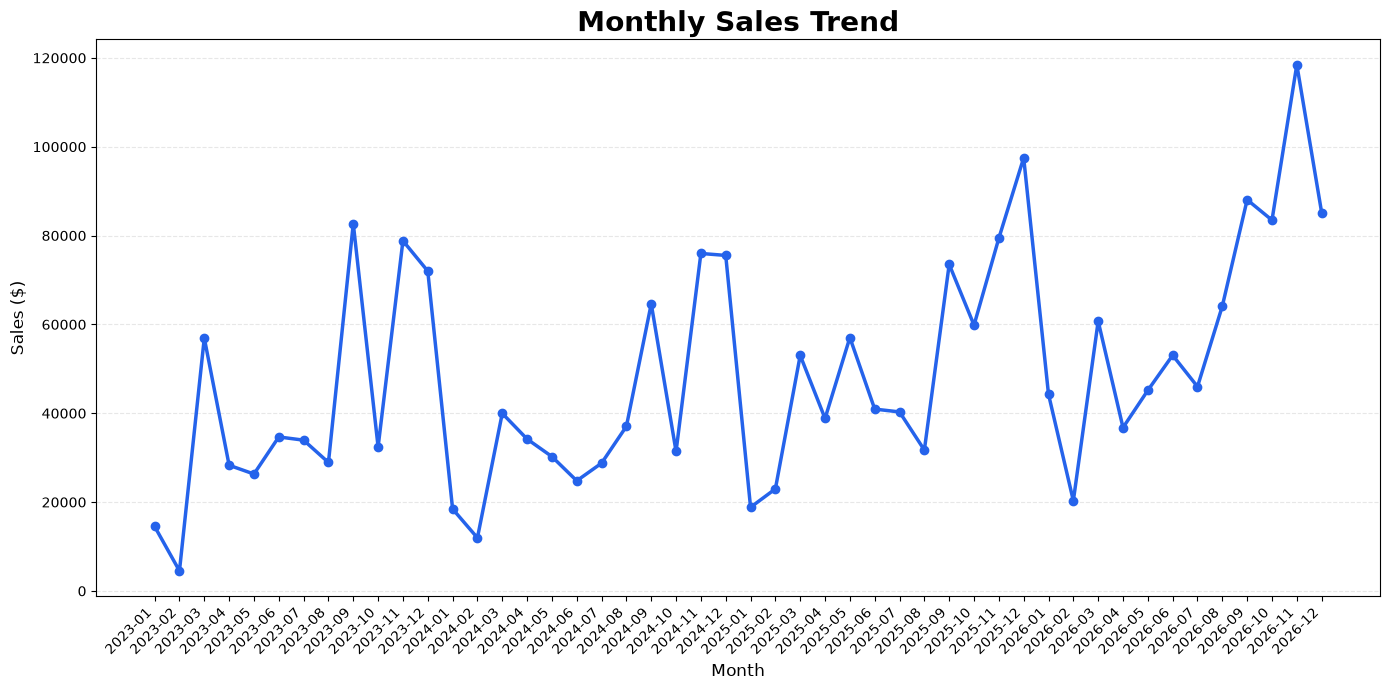

In [12]:
# Monthly Sales Trend

plt.figure(figsize=(14, 7))

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Sales"],
    marker="o",
    linewidth=2.5,
    color="#2563EB"
)

plt.title(
    "Monthly Sales Trend",
    fontsize=20,
    fontweight="bold"
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Sales ($)", fontsize=12)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

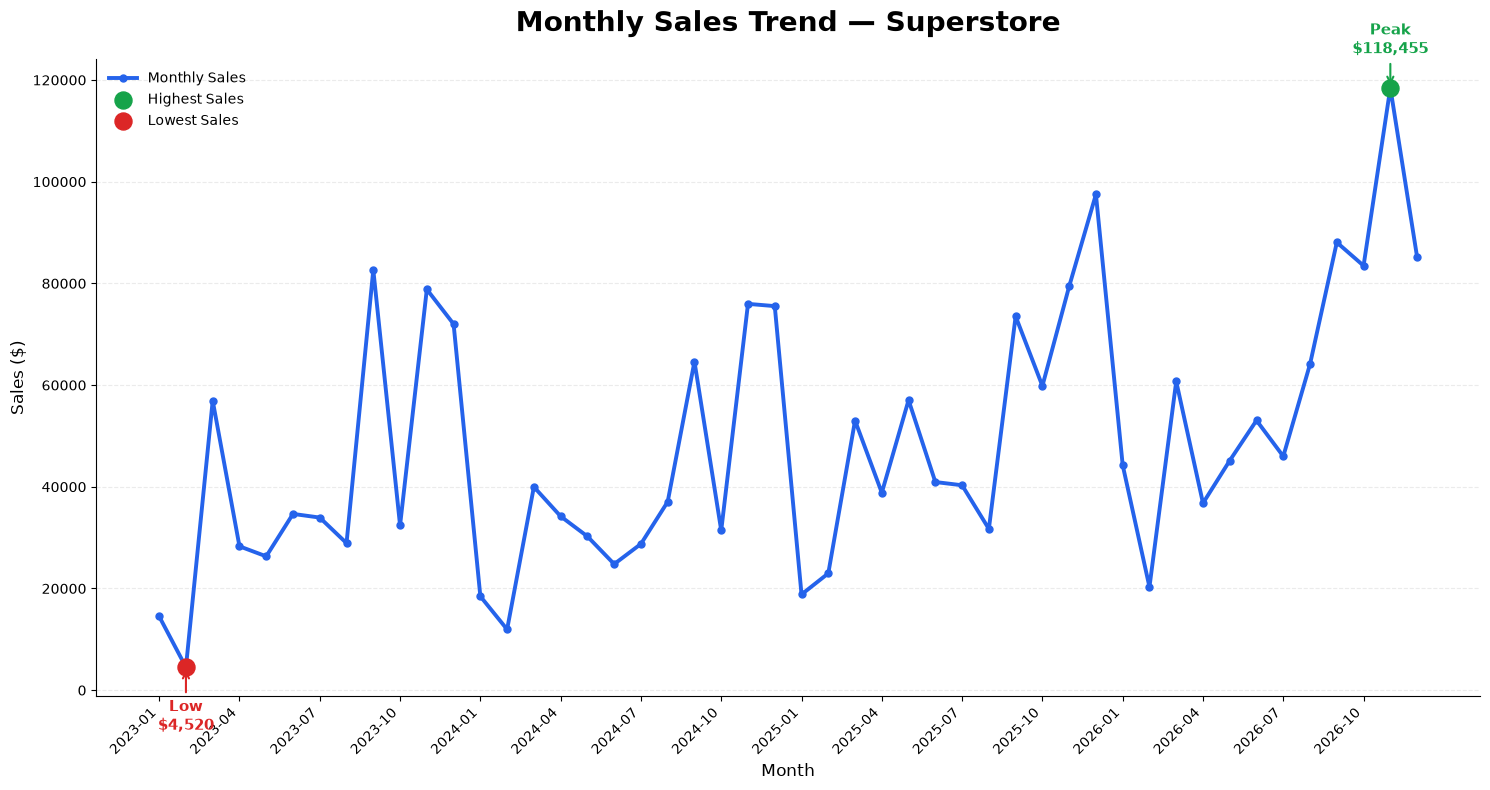

In [13]:
# Create an improved Monthly Sales Trend visualization

plt.figure(figsize=(15, 8))

# Main sales trend line
plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Sales"],
    color="#2563EB",
    linewidth=2.8,
    marker="o",
    markersize=5,
    label="Monthly Sales"
)

# Find highest and lowest sales months
max_index = monthly_sales["Sales"].idxmax()
min_index = monthly_sales["Sales"].idxmin()

max_month = monthly_sales.loc[max_index, "Year-Month"]
max_sales = monthly_sales.loc[max_index, "Sales"]

min_month = monthly_sales.loc[min_index, "Year-Month"]
min_sales = monthly_sales.loc[min_index, "Sales"]

# Highlight highest sales
plt.scatter(
    max_month,
    max_sales,
    color="#16A34A",
    s=150,
    zorder=5,
    label="Highest Sales"
)

# Highlight lowest sales
plt.scatter(
    min_month,
    min_sales,
    color="#DC2626",
    s=150,
    zorder=5,
    label="Lowest Sales"
)

# Annotate highest sales
plt.annotate(
    f"Peak\n${max_sales:,.0f}",
    xy=(max_month, max_sales),
    xytext=(0, 25),
    textcoords="offset points",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#16A34A",
    arrowprops=dict(
        arrowstyle="->",
        color="#16A34A",
        lw=1.5
    )
)

# Annotate lowest sales
plt.annotate(
    f"Low\n${min_sales:,.0f}",
    xy=(min_month, min_sales),
    xytext=(0, -45),
    textcoords="offset points",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#DC2626",
    arrowprops=dict(
        arrowstyle="->",
        color="#DC2626",
        lw=1.5
    )
)

# Title and labels
plt.title(
    "Monthly Sales Trend — Superstore",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Sales ($)", fontsize=12)

# Reduce x-axis clutter
tick_positions = range(0, len(monthly_sales), 3)

plt.xticks(
    tick_positions,
    monthly_sales["Year-Month"].iloc[tick_positions],
    rotation=45,
    ha="right"
)

# Add horizontal grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# Remove unnecessary top/right borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.legend(
    frameon=False,
    loc="upper left"
)

plt.tight_layout()

plt.show()

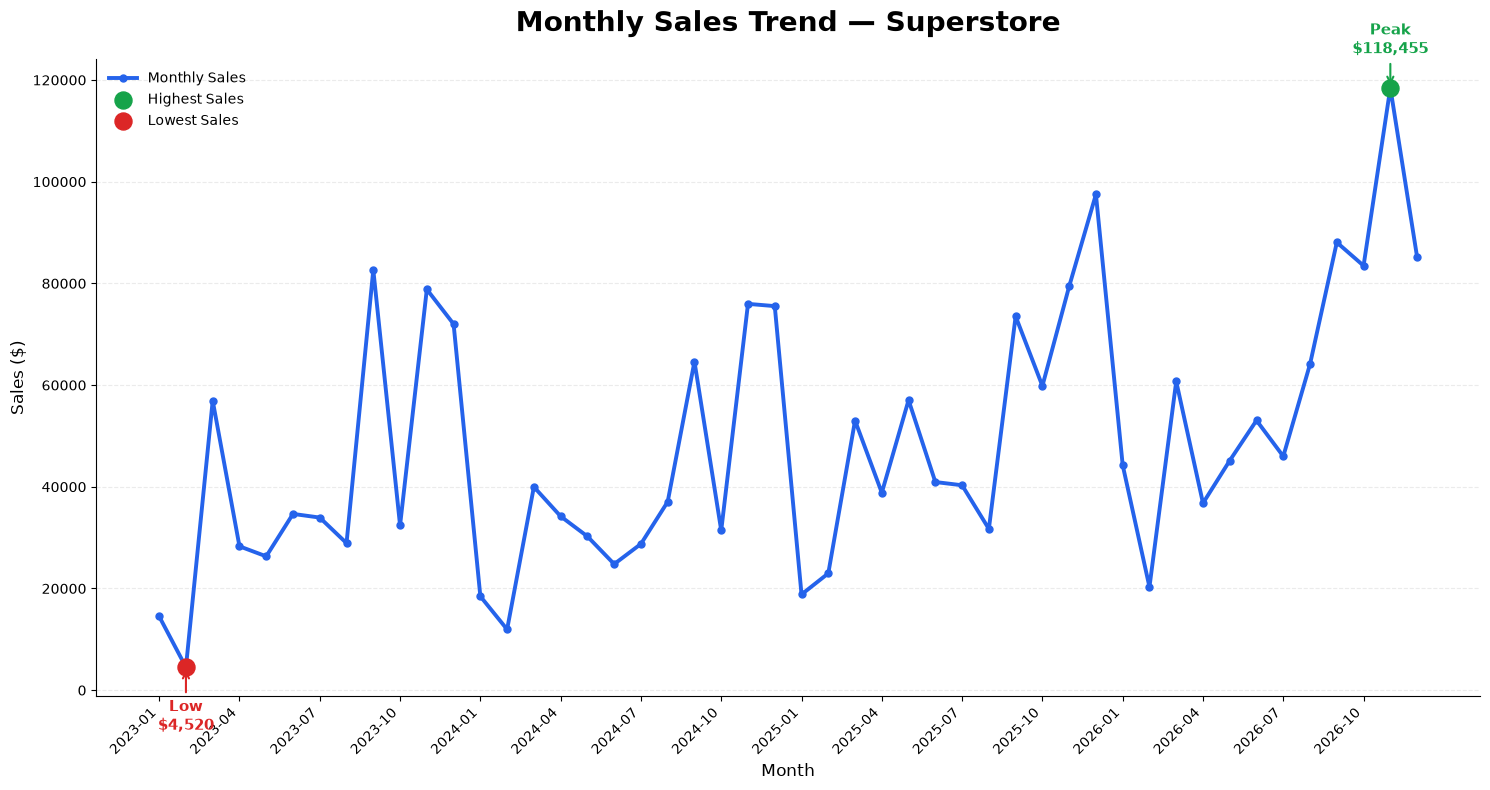

Chart saved successfully to: ../outputs/charts/monthly_sales_trend.png


In [21]:
# Save the visualization

output_path = "../outputs/charts/monthly_sales_trend.png"

plt.figure(figsize=(15, 8))

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Sales"],
    color="#2563EB",
    linewidth=2.8,
    marker="o",
    markersize=5,
    label="Monthly Sales"
)

plt.scatter(
    max_month,
    max_sales,
    color="#16A34A",
    s=150,
    zorder=5,
    label="Highest Sales"
)

plt.scatter(
    min_month,
    min_sales,
    color="#DC2626",
    s=150,
    zorder=5,
    label="Lowest Sales"
)

plt.annotate(
    f"Peak\n${max_sales:,.0f}",
    xy=(max_month, max_sales),
    xytext=(0, 25),
    textcoords="offset points",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#16A34A",
    arrowprops=dict(
        arrowstyle="->",
        color="#16A34A",
        lw=1.5
    )
)

plt.annotate(
    f"Low\n${min_sales:,.0f}",
    xy=(min_month, min_sales),
    xytext=(0, -45),
    textcoords="offset points",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#DC2626",
    arrowprops=dict(
        arrowstyle="->",
        color="#DC2626",
        lw=1.5
    )
)

plt.title(
    "Monthly Sales Trend — Superstore",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Sales ($)", fontsize=12)

plt.xticks(
    tick_positions,
    monthly_sales["Year-Month"].iloc[tick_positions],
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.legend(frameon=False, loc="upper left")

plt.tight_layout()

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved successfully to: {output_path}")

In [21]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
c:\Users\srinu\OneDrive\Desktop\code alpha data visualization\notebooks


In [22]:
import os

output_folder = "../outputs/charts"

print("Folder exists:", os.path.exists(output_folder))
print("Is it a directory:", os.path.isdir(output_folder))

Folder exists: True
Is it a directory: True


In [23]:
from pathlib import Path

# Get the project root directory
project_root = Path.cwd().parent

# Create the charts folder if it doesn't exist
charts_folder = project_root / "outputs" / "charts"
charts_folder.mkdir(parents=True, exist_ok=True)

# Define the output file
output_path = charts_folder / "monthly_sales_trend.png"

print("Saving chart to:")
print(output_path)

Saving chart to:
c:\Users\srinu\OneDrive\Desktop\code alpha data visualization\outputs\charts\monthly_sales_trend.png


In [22]:
# Calculate monthly profit

monthly_profit = (
    df.groupby("Year-Month")["Profit"]
    .sum()
    .reset_index()
)

monthly_profit["Year-Month"] = monthly_profit["Year-Month"].astype(str)

print("Monthly profit calculated successfully!")
monthly_profit.head()

Monthly profit calculated successfully!


,Year-Month,Profit
0,2023-01,2539.3907
1,2023-02,862.3084
2,2023-03,693.4499
3,2023-04,3488.8352
4,2023-05,3196.3918


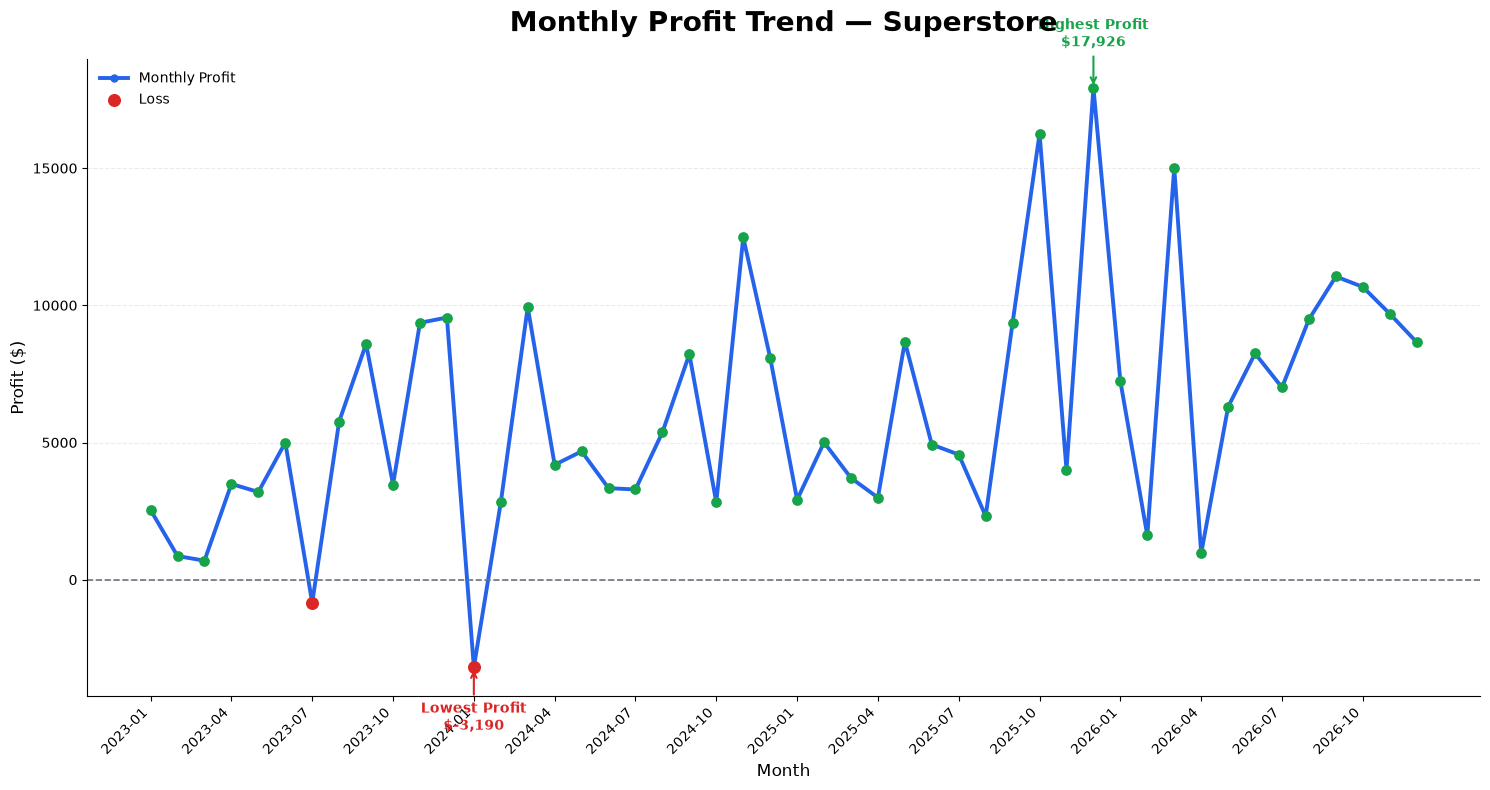

Monthly profit chart saved successfully!


In [56]:
# Monthly Profit Trend

plt.figure(figsize=(15, 8))

# Main profit trend
plt.plot(
    monthly_profit["Year-Month"],
    monthly_profit["Profit"],
    color="#2563EB",
    linewidth=2.8,
    marker="o",
    markersize=5,
    label="Monthly Profit"
)

# Highlight positive and negative points
positive_profit = monthly_profit["Profit"] >= 0
negative_profit = monthly_profit["Profit"] < 0

plt.scatter(
    monthly_profit.loc[positive_profit, "Year-Month"],
    monthly_profit.loc[positive_profit, "Profit"],
    color="#16A34A",
    s=45,
    zorder=5
)

plt.scatter(
    monthly_profit.loc[negative_profit, "Year-Month"],
    monthly_profit.loc[negative_profit, "Profit"],
    color="#DC2626",
    s=70,
    zorder=5,
    label="Loss"
)

# Zero-profit reference line
plt.axhline(
    y=0,
    color="#6B7280",
    linestyle="--",
    linewidth=1.2
)

# Find highest and lowest profit
max_profit_index = monthly_profit["Profit"].idxmax()
min_profit_index = monthly_profit["Profit"].idxmin()

max_profit_month = monthly_profit.loc[max_profit_index, "Year-Month"]
max_profit = monthly_profit.loc[max_profit_index, "Profit"]

min_profit_month = monthly_profit.loc[min_profit_index, "Year-Month"]
min_profit = monthly_profit.loc[min_profit_index, "Profit"]

# Highlight highest profit
plt.annotate(
    f"Highest Profit\n${max_profit:,.0f}",
    xy=(max_profit_month, max_profit),
    xytext=(0, 30),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#16A34A",
    arrowprops=dict(
        arrowstyle="->",
        color="#16A34A",
        lw=1.5
    )
)

# Highlight lowest profit
plt.annotate(
    f"Lowest Profit\n${min_profit:,.0f}",
    xy=(min_profit_month, min_profit),
    xytext=(0, -45),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#DC2626",
    arrowprops=dict(
        arrowstyle="->",
        color="#DC2626",
        lw=1.5
    )
)

# Title
plt.title(
    "Monthly Profit Trend — Superstore",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Profit ($)", fontsize=12)

# Reduce x-axis clutter
tick_positions = range(0, len(monthly_profit), 3)

plt.xticks(
    tick_positions,
    monthly_profit["Year-Month"].iloc[tick_positions],
    rotation=45,
    ha="right"
)

# Grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# Clean borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.legend(
    frameon=False,
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    charts_folder / "monthly_profit_trend.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Monthly profit chart saved successfully!")

plt.show()

In [15]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Category sales calculated successfully!")
category_sales

Category sales calculated successfully!


,Category,Sales
0,Technology,839893.2790
1,Furniture,754747.7613
2,Office Supplies,731893.3140


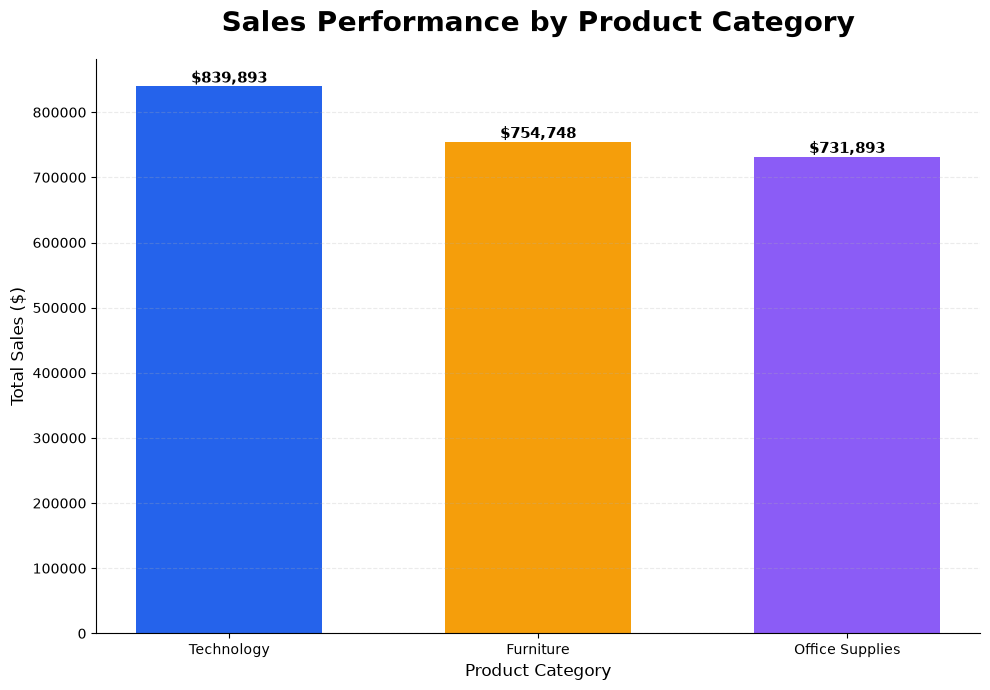

3. Sales by category saved!


In [24]:
# Sales by Category

plt.figure(figsize=(10, 7))

colors = ["#2563EB", "#F59E0B", "#8B5CF6"]

bars = plt.bar(
    category_sales["Category"],
    category_sales["Sales"],
    color=colors,
    width=0.6
)

# Add sales values above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Sales Performance by Product Category",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Sales ($)", fontsize=12)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)




plt.tight_layout()
plt.savefig(
    charts_folder / "sales_by_category.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("3. Sales by category saved!")

plt.show()

In [25]:
# Calculate total profit by category

category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Category profit calculated successfully!")
category_profit

Category profit calculated successfully!


,Category,Profit
0,Technology,146543.3756
1,Office Supplies,126023.4434
2,Furniture,19729.9956


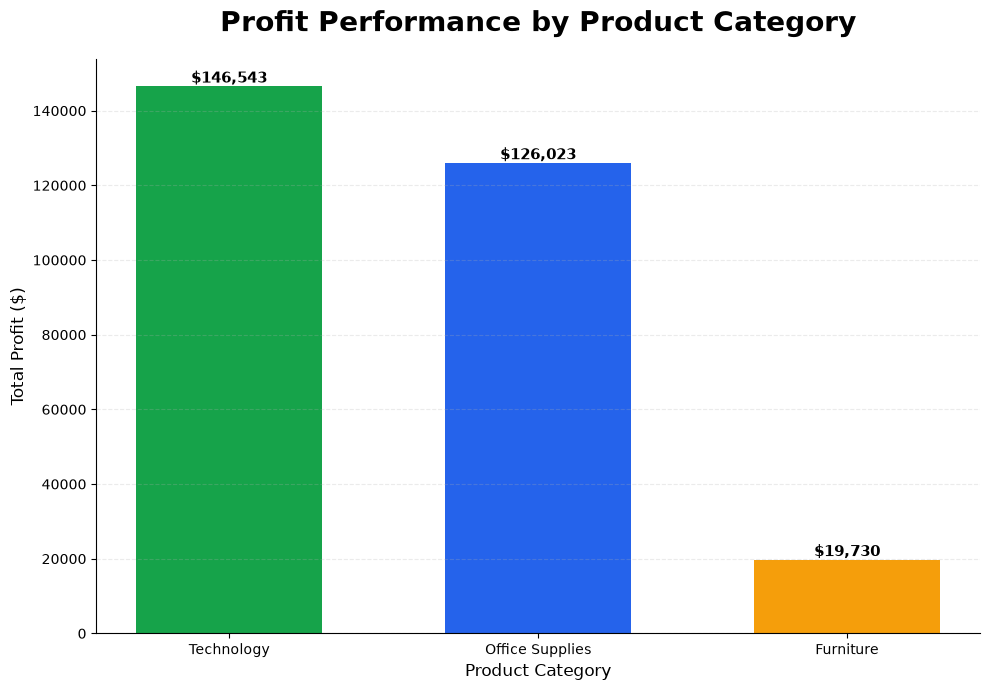

4. Profit by category saved!


In [26]:
# Profit by Category

plt.figure(figsize=(10, 7))

# Color based on profit ranking
colors = ["#16A34A", "#2563EB", "#F59E0B"]

bars = plt.bar(
    category_profit["Category"],
    category_profit["Profit"],
    color=colors,
    width=0.6
)

# Add profit values above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Profit Performance by Product Category",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Profit ($)", fontsize=12)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    charts_folder / "profit_by_category.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("4. Profit by category saved!")

plt.show()

In [27]:
# Combine sales and profit by category

category_performance = (
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
    .reset_index()
)

print("Category performance calculated successfully!")
category_performance

Category performance calculated successfully!


,Category,Sales,Profit
0,Technology,839893.2790,146543.3756
1,Furniture,754747.7613,19729.9956
2,Office Supplies,731893.3140,126023.4434


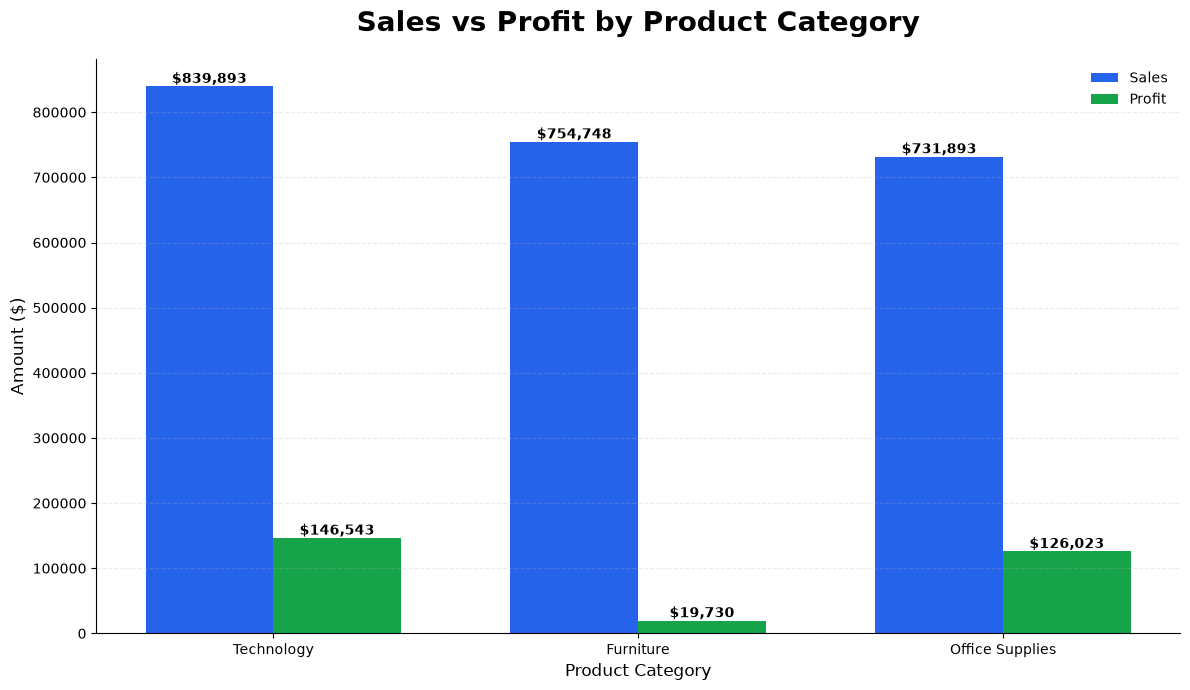

5. Sales vs profit by category saved!


In [28]:
# Sales vs Profit by Category

x = range(len(category_performance))
width = 0.35

plt.figure(figsize=(12, 7))

# Sales bars
sales_bars = plt.bar(
    [i - width / 2 for i in x],
    category_performance["Sales"],
    width=width,
    color="#2563EB",
    label="Sales"
)

# Profit bars
profit_bars = plt.bar(
    [i + width / 2 for i in x],
    category_performance["Profit"],
    width=width,
    color="#16A34A",
    label="Profit"
)

# Add values above bars
for bar in sales_bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

for bar in profit_bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# Titles and labels
plt.title(
    "Sales vs Profit by Product Category",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Amount ($)", fontsize=12)

plt.xticks(
    x,
    category_performance["Category"]
)

plt.legend(
    frameon=False
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# Clean borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    charts_folder / "sales_vs_profit_category.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("5. Sales vs profit by category saved!")

plt.show()

In [29]:
# Calculate top 10 sub-categories by sales

top_subcategories = (
    df.groupby("Sub-Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
    .reset_index()
)

print("Top 10 sub-categories calculated successfully!")
top_subcategories

Top 10 sub-categories calculated successfully!


,Sub-Category,Sales
0,Appliances,108213.1850
1,Bookcases,115361.2043
2,Copiers,150745.2900
3,Accessories,167380.3180
4,Machines,189925.0310
5,Binders,207354.8810
6,Tables,208020.1820
7,Storage,224644.5540
8,Phones,331842.6400
9,Chairs,335768.2490


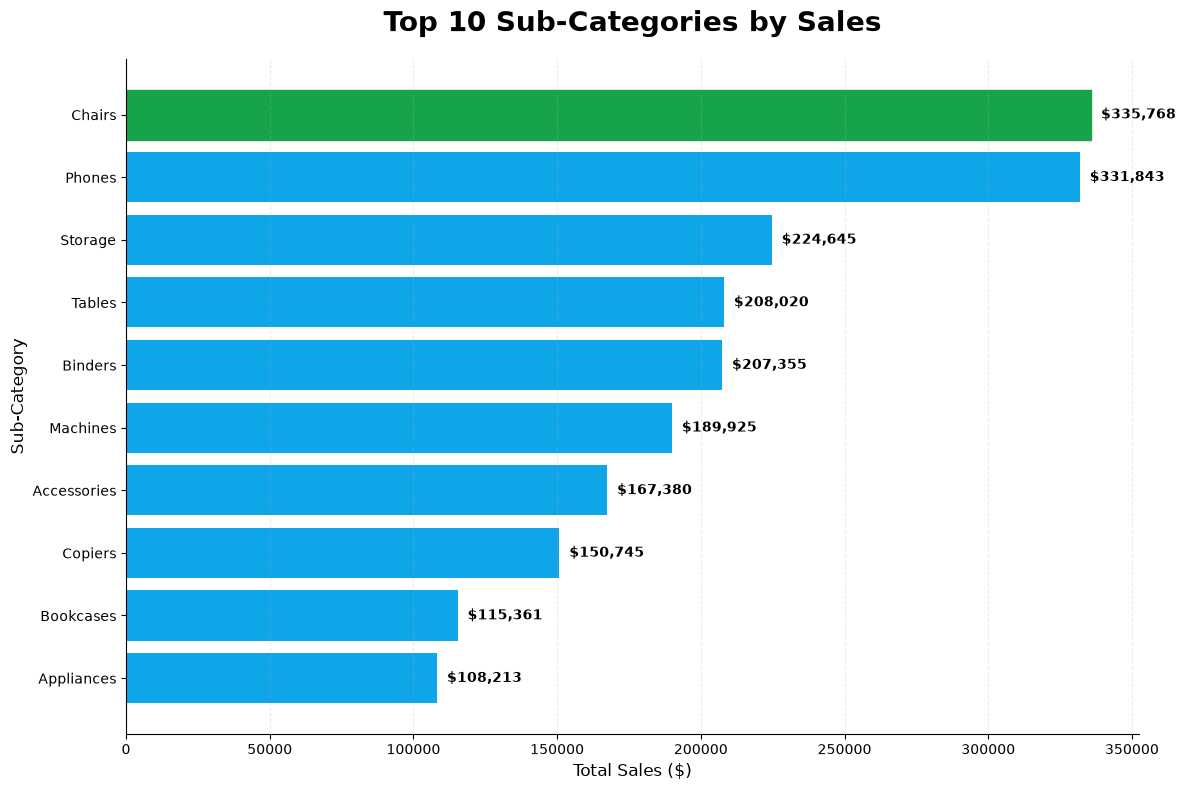

6. Top 10 sub-categories by sales saved!


In [30]:
# Top 10 Sub-Categories by Sales

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top_subcategories["Sub-Category"],
    top_subcategories["Sales"],
    color="#0EA5E9"
)

# Highlight the highest-selling sub-category
highest_index = top_subcategories["Sales"].idxmax()

for i, bar in enumerate(bars):
    if i == highest_index:
        bar.set_color("#16A34A")

# Add sales values
for bar in bars:
    width = bar.get_width()

    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"  ${width:,.0f}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Top 10 Sub-Categories by Sales",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Total Sales ($)", fontsize=12)
plt.ylabel("Sub-Category", fontsize=12)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    charts_folder / "top_10_subcategories_sales.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("6. Top 10 sub-categories by sales saved!")

plt.show()

In [31]:
top_profit_subcategories = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
    .reset_index()
)

print("Top 10 sub-categories by profit calculated successfully!")
top_profit_subcategories

Top 10 sub-categories by profit calculated successfully!


,Sub-Category,Profit
0,Envelopes,6988.0247
1,Furnishings,13891.7430
2,Appliances,18329.4844
3,Storage,21285.1115
4,Chairs,27223.5323
5,Binders,31426.1003
6,Paper,34511.5070
7,Accessories,41936.6357
8,Phones,45050.8265
9,Copiers,56093.9365


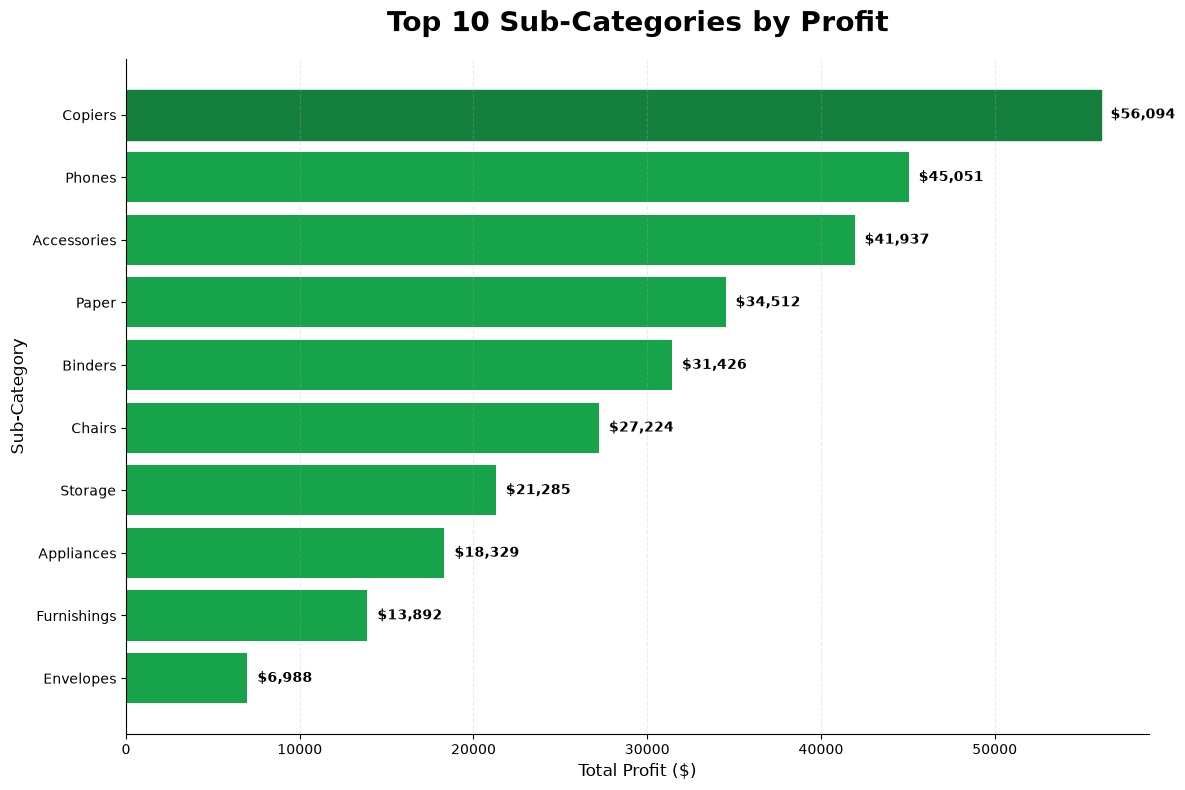

7. Top 10 sub-categories by profit saved!


In [32]:
plt.figure(figsize=(12, 8))

bars = plt.barh(
    top_profit_subcategories["Sub-Category"],
    top_profit_subcategories["Profit"],
    color="#16A34A"
)

# Highlight the highest-profit sub-category
highest_index = top_profit_subcategories["Profit"].idxmax()

for i, bar in enumerate(bars):
    if i == highest_index:
        bar.set_color("#15803D")

# Add profit values
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"  ${width:,.0f}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Top 10 Sub-Categories by Profit",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Total Profit ($)", fontsize=12)
plt.ylabel("Sub-Category", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.25)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    charts_folder / "top_10_subcategories_profit.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("7. Top 10 sub-categories by profit saved!")
plt.show()

In [33]:
region_performance = (
    df.groupby("Region")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
    .reset_index()
)

print("Regional performance calculated successfully!")
region_performance

Regional performance calculated successfully!


,Region,Sales,Profit
0,West,739813.6085,110798.8170
1,East,691828.1680,94883.2603
2,Central,503170.6728,39865.3070
3,South,391721.9050,46749.4303


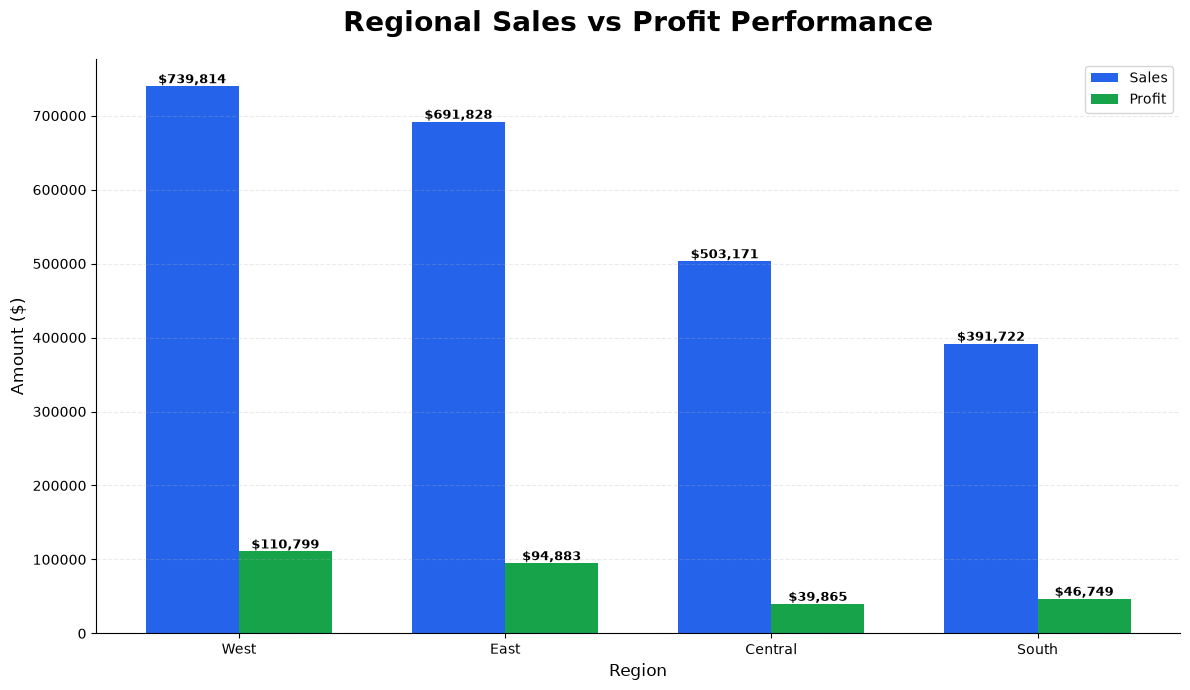

8. Regional performance saved!


In [34]:
plt.figure(figsize=(12, 7))

x = range(len(region_performance))
width = 0.35

sales_bars = plt.bar(
    [i - width/2 for i in x],
    region_performance["Sales"],
    width=width,
    label="Sales",
    color="#2563EB"
)

profit_bars = plt.bar(
    [i + width/2 for i in x],
    region_performance["Profit"],
    width=width,
    label="Profit",
    color="#16A34A"
)

# Add values above bars
for bar in sales_bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

for bar in profit_bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

plt.xticks(x, region_performance["Region"])

plt.title(
    "Regional Sales vs Profit Performance",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Region", fontsize=12)
plt.ylabel("Amount ($)", fontsize=12)

plt.legend()

plt.grid(axis="y", linestyle="--", alpha=0.25)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    charts_folder / "regional_sales_profit.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("8. Regional performance saved!")
plt.show()

In [35]:
segment_sales = (
    df.groupby("Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Sales by segment calculated successfully!")
segment_sales

Sales by segment calculated successfully!


,Segment,Sales
0,Consumer,1.170660e+06
1,Corporate,7.158061e+05
2,Home Office,4.400684e+05


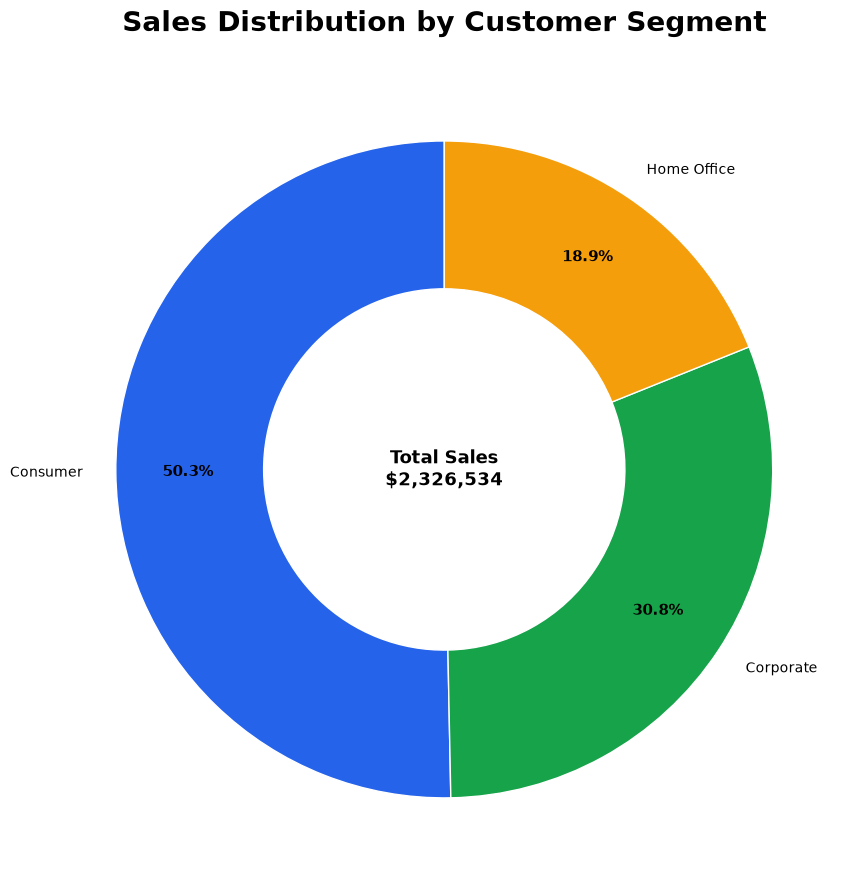

9. Sales by segment saved!


In [36]:
plt.figure(figsize=(9, 9))

colors = ["#2563EB", "#16A34A", "#F59E0B"]

wedges, texts, autotexts = plt.pie(
    segment_sales["Sales"],
    labels=segment_sales["Segment"],
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops=dict(width=0.45, edgecolor="white"),
    pctdistance=0.78
)

plt.title(
    "Sales Distribution by Customer Segment",
    fontsize=20,
    fontweight="bold",
    pad=20
)

# Make percentage labels bold
for autotext in autotexts:
    autotext.set_fontweight("bold")
    autotext.set_fontsize(11)

# Add total sales in the center
total_sales = segment_sales["Sales"].sum()

plt.text(
    0,
    0,
    f"Total Sales\n${total_sales:,.0f}",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    charts_folder / "sales_by_segment.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("9. Sales by segment saved!")
plt.show()

In [37]:
yearly_performance = (
    df.groupby("Year")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)

print("Yearly performance calculated successfully!")
yearly_performance

Yearly performance calculated successfully!


,Year,Sales,Profit
0,2023,494040.2121,51684.2957
1,2024,472993.0310,62020.9695
2,2025,613933.5800,82665.2018
3,2026,745567.5312,95926.3476


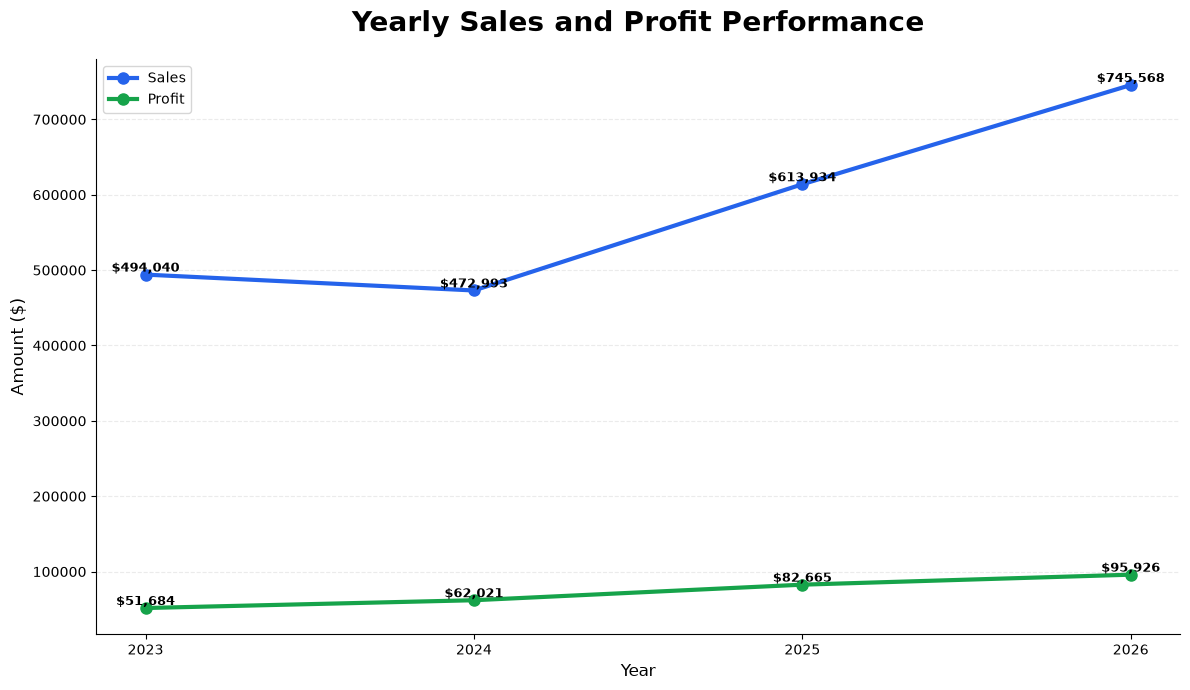

10. Yearly sales and profit saved!


In [38]:
plt.figure(figsize=(12, 7))

plt.plot(
    yearly_performance["Year"],
    yearly_performance["Sales"],
    marker="o",
    linewidth=3,
    markersize=8,
    color="#2563EB",
    label="Sales"
)

plt.plot(
    yearly_performance["Year"],
    yearly_performance["Profit"],
    marker="o",
    linewidth=3,
    markersize=8,
    color="#16A34A",
    label="Profit"
)

# Add values to Sales
for x, y in zip(yearly_performance["Year"], yearly_performance["Sales"]):
    plt.text(
        x, y,
        f"${y:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# Add values to Profit
for x, y in zip(yearly_performance["Year"], yearly_performance["Profit"]):
    plt.text(
        x, y,
        f"${y:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

plt.title(
    "Yearly Sales and Profit Performance",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Amount ($)", fontsize=12)

plt.xticks(yearly_performance["Year"])

plt.grid(axis="y", linestyle="--", alpha=0.25)

plt.legend()

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    charts_folder / "yearly_sales_profit.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("10. Yearly sales and profit saved!")
plt.show()

In [39]:
discount_profit = (
    df.groupby("Discount")["Profit"]
    .sum()
    .reset_index()
)

print("Discount vs profit calculated successfully!")
discount_profit

Discount vs profit calculated successfully!


,Discount,Profit
0,0.00,326718.5872
1,0.10,9099.9700
2,0.15,1418.9915
3,0.20,91079.9517
4,0.30,-10513.4456
5,0.32,-2391.1377
6,0.40,-23086.3742
7,0.45,-2493.1111
8,0.50,-20506.4281
9,0.60,-6164.3472


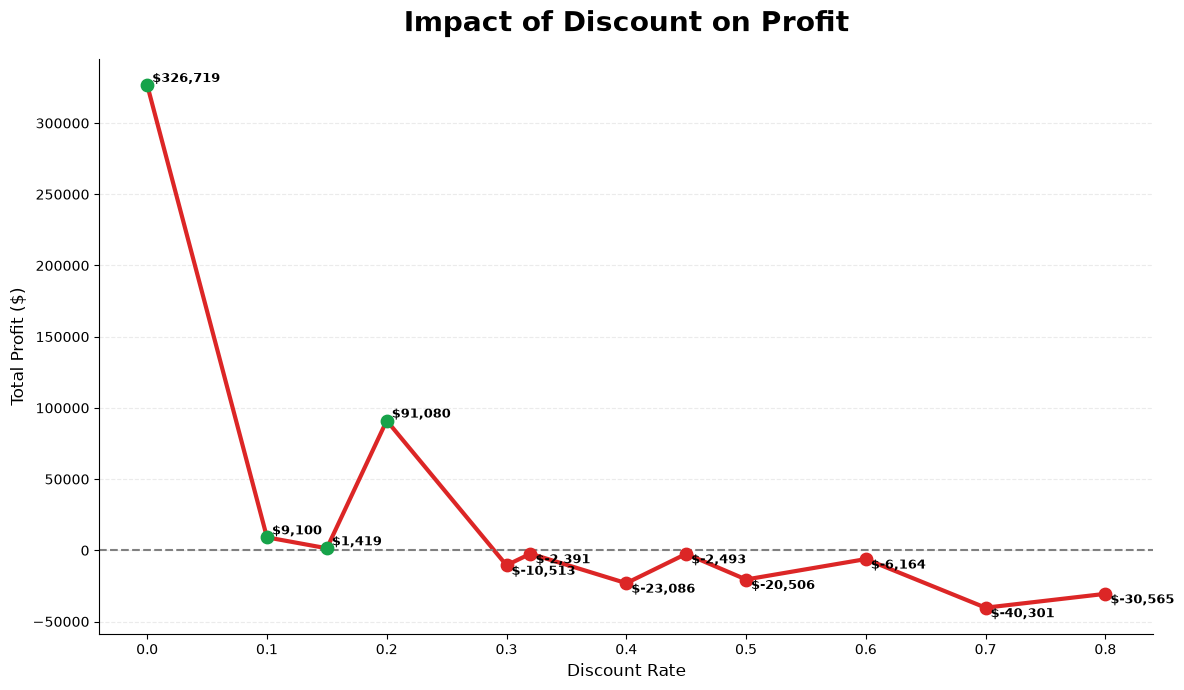

11. Discount vs profit saved!


In [40]:
plt.figure(figsize=(12, 7))

plt.plot(
    discount_profit["Discount"],
    discount_profit["Profit"],
    marker="o",
    linewidth=3,
    markersize=8,
    color="#DC2626"
)

# Highlight profitable and loss-making points
for x, y in zip(discount_profit["Discount"], discount_profit["Profit"]):
    if y >= 0:
        plt.scatter(x, y, color="#16A34A", s=80, zorder=3)
    else:
        plt.scatter(x, y, color="#DC2626", s=80, zorder=3)

    plt.text(
        x,
        y,
        f" ${y:,.0f}",
        fontsize=9,
        fontweight="bold",
        va="bottom" if y >= 0 else "top"
    )

# Zero-profit reference line
plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1.5
)

plt.title(
    "Impact of Discount on Profit",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Discount Rate", fontsize=12)
plt.ylabel("Total Profit ($)", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.25)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    charts_folder / "discount_vs_profit.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("11. Discount vs profit saved!")
plt.show()

In [41]:
category_margin = (
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)

category_margin["Profit Margin (%)"] = (
    category_margin["Profit"] / category_margin["Sales"] * 100
)

category_margin = category_margin.sort_values(
    "Profit Margin (%)",
    ascending=False
)

print("Profit margin calculated successfully!")
category_margin

Profit margin calculated successfully!


,Category,Sales,Profit,Profit Margin (%)
2,Technology,839893.2790,146543.3756,17.447857
1,Office Supplies,731893.3140,126023.4434,17.218827
0,Furniture,754747.7613,19729.9956,2.614118


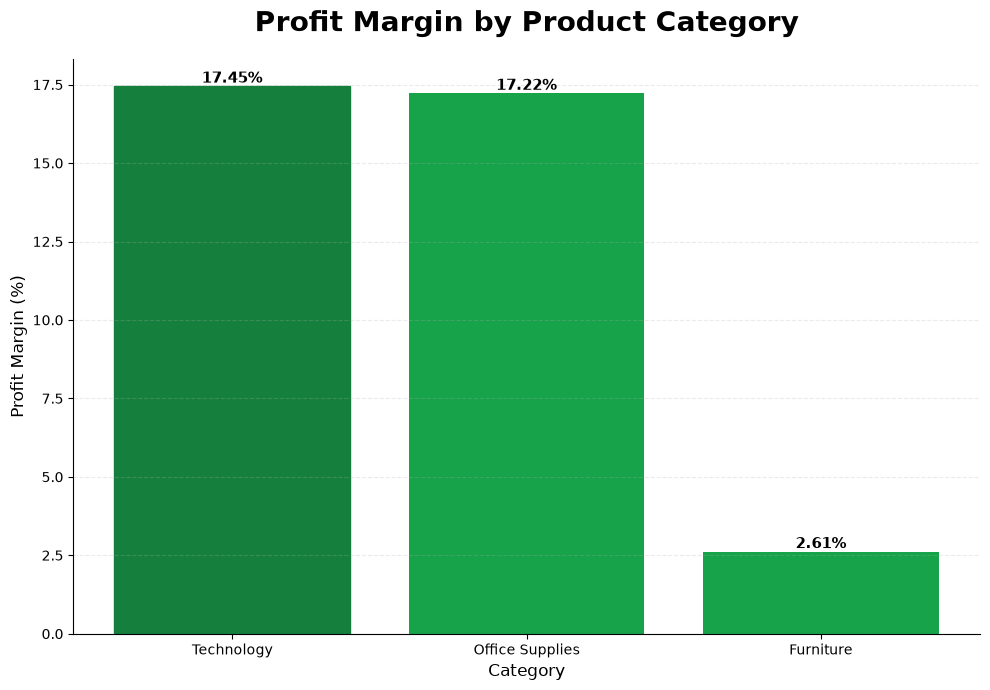

12. Profit margin by category saved!


In [42]:
plt.figure(figsize=(10, 7))

bars = plt.bar(
    category_margin["Category"],
    category_margin["Profit Margin (%)"],
    color="#16A34A"
)

# Highlight highest margin
highest_index = category_margin["Profit Margin (%)"].idxmax()

for i, bar in enumerate(bars):
    if category_margin.iloc[i]["Profit Margin (%)"] == category_margin["Profit Margin (%)"].max():
        bar.set_color("#15803D")

# Add percentage labels
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Profit Margin by Product Category",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Category", fontsize=12)
plt.ylabel("Profit Margin (%)", fontsize=12)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    charts_folder / "profit_margin_category.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("12. Profit margin by category saved!")
plt.show()

In [43]:
correlation_data = df[["Sales", "Quantity", "Discount", "Profit"]]

correlation_matrix = correlation_data.corr()

print("Correlation matrix calculated successfully!")
correlation_matrix

Correlation matrix calculated successfully!


,Sales,Quantity,Discount,Profit
Sales,1.000000,0.198457,-0.027756,0.481460
Quantity,0.198457,1.000000,0.007475,0.066145
Discount,-0.027756,0.007475,1.000000,-0.218882
Profit,0.481460,0.066145,-0.218882,1.000000


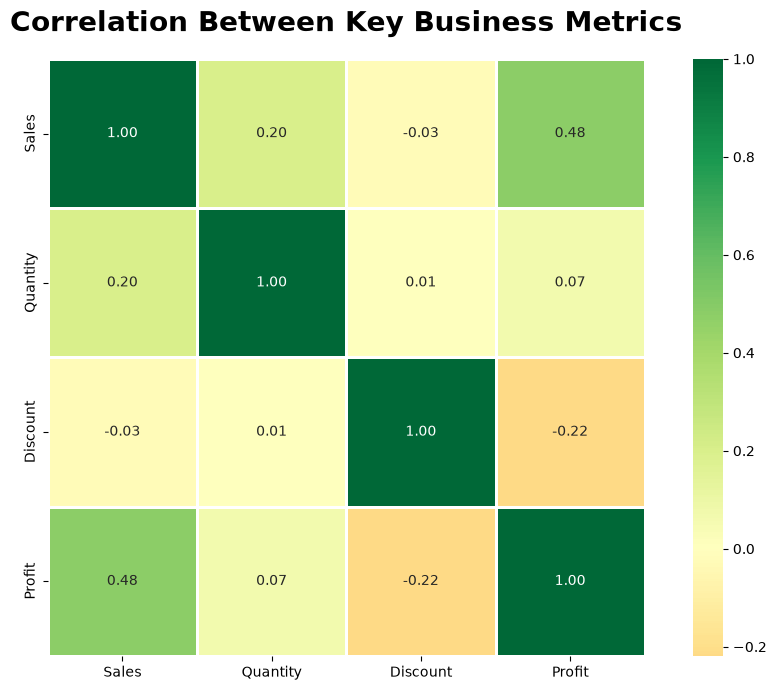

13. Correlation heatmap saved!


In [44]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=1,
    square=True
)

plt.title(
    "Correlation Between Key Business Metrics",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.savefig(
    charts_folder / "correlation_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("13. Correlation heatmap saved!")
plt.show()

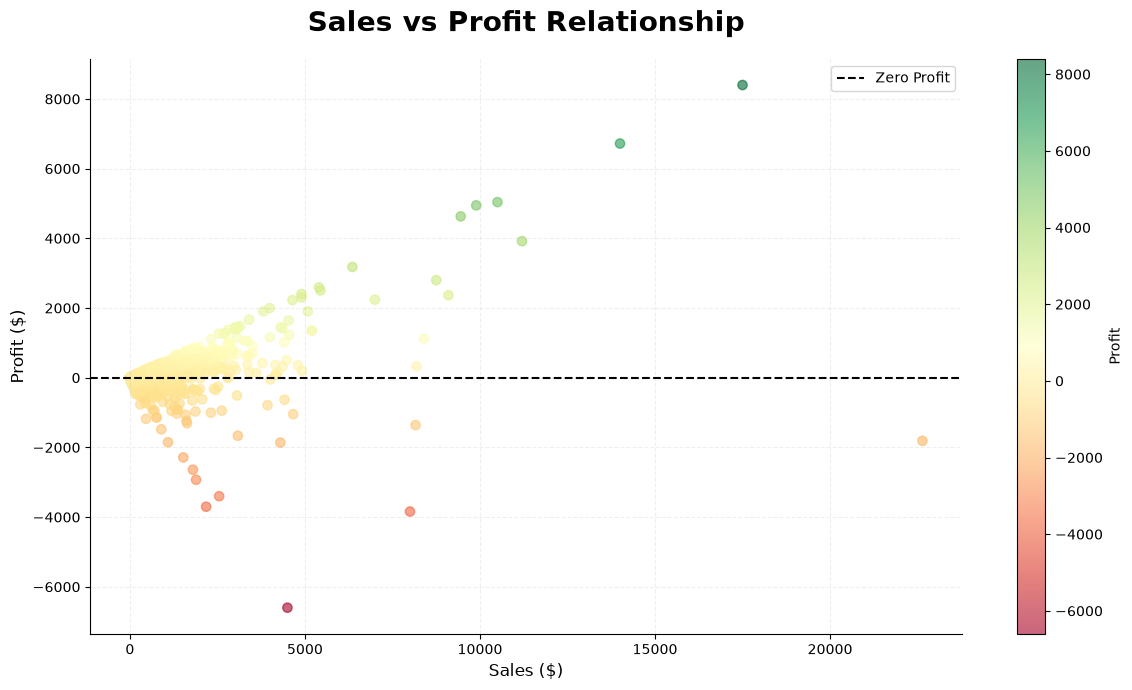

14. Sales vs profit scatter saved!


In [45]:
plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    df["Sales"],
    df["Profit"],
    c=df["Profit"],
    cmap="RdYlGn",
    alpha=0.6,
    s=45
)

# Zero-profit reference line
plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Zero Profit"
)

plt.colorbar(
    scatter,
    label="Profit"
)

plt.title(
    "Sales vs Profit Relationship",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Sales ($)", fontsize=12)
plt.ylabel("Profit ($)", fontsize=12)

plt.grid(
    linestyle="--",
    alpha=0.2
)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.legend()

plt.tight_layout()
plt.savefig(
    charts_folder / "sales_vs_profit.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("14. Sales vs profit scatter saved!")
plt.show()

In [46]:
top_products_profit = (
    df.groupby("Product Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
    .reset_index()
)

print("Top 10 most profitable products calculated successfully!")
top_products_profit

Top 10 most profitable products calculated successfully!


,Product Name,Profit
0,Zebra ZM400 Thermal Label Printer,3343.5360
1,Ibico EPK-21 Electric Binding System,3345.2823
2,Plantronics Savi W720 Multi-Device Wireless He...,3696.2820
3,"3D Systems Cube Printer, 2nd Generation, Magenta",3717.9714
4,Ativa V4110MDD Micro-Cut Shredder,3772.9461
5,HP Designjet T520 Inkjet Large Format Printer ...,4094.9766
6,Canon PC1060 Personal Laser Copier,4570.9347
7,Hewlett Packard LaserJet 3310 Copier,6983.8836
8,Fellowes PB500 Electric Punch Plastic Comb Bin...,7753.0390
9,Canon imageCLASS 2200 Advanced Copier,25199.9280


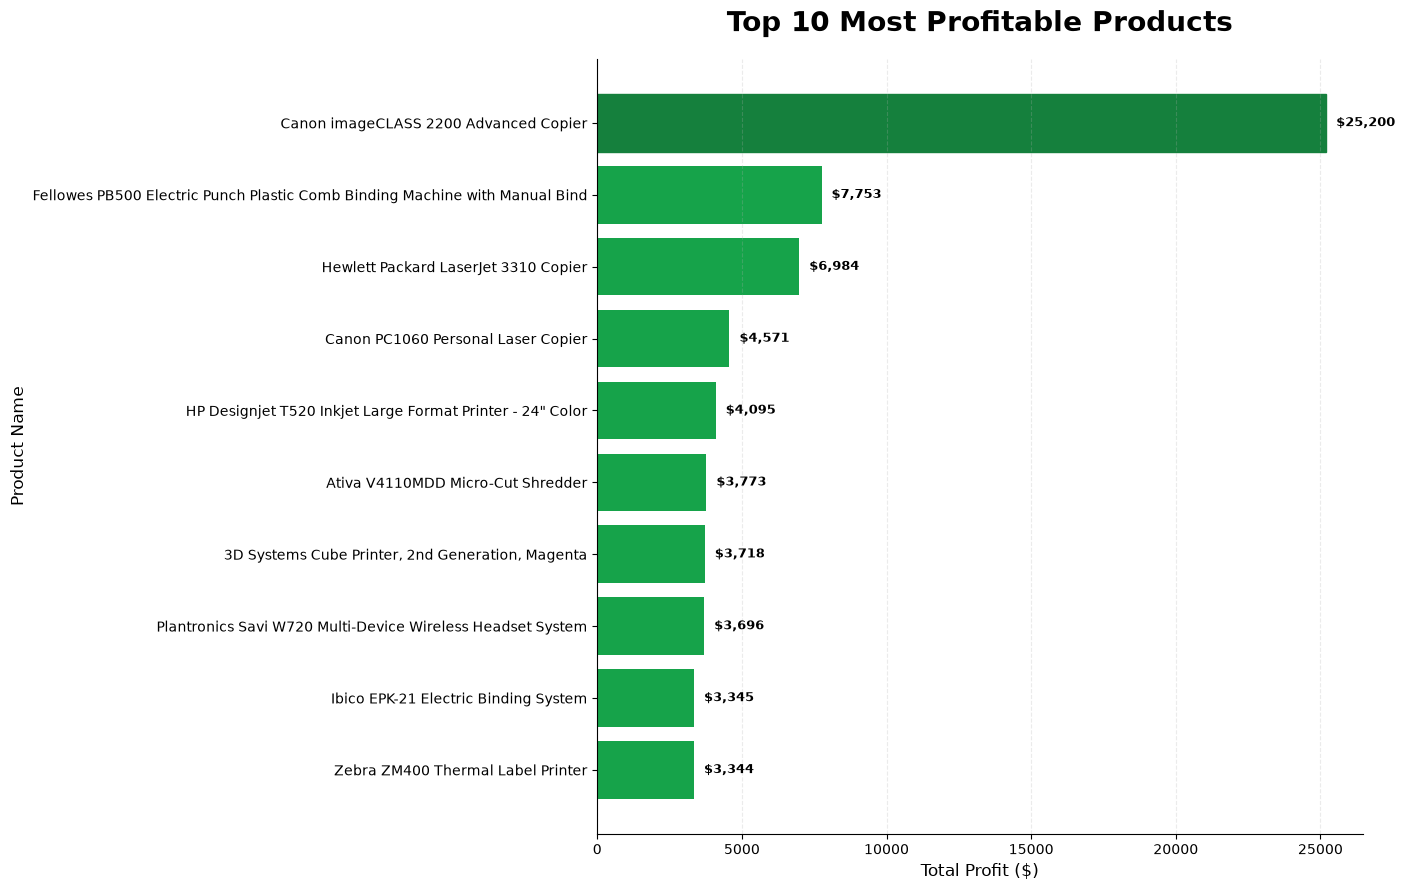

15. Top 10 profitable products saved!


In [47]:
plt.figure(figsize=(14, 9))

bars = plt.barh(
    top_products_profit["Product Name"],
    top_products_profit["Profit"],
    color="#16A34A"
)

# Highlight the #1 product
highest_profit = top_products_profit["Profit"].max()

for i, bar in enumerate(bars):
    if top_products_profit.iloc[i]["Profit"] == highest_profit:
        bar.set_color("#15803D")

# Add profit values
for bar in bars:
    width = bar.get_width()

    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"  ${width:,.0f}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title(
    "Top 10 Most Profitable Products",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xlabel("Total Profit ($)", fontsize=12)
plt.ylabel("Product Name", fontsize=12)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    charts_folder / "top_10_profitable_products.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("15. Top 10 profitable products saved!")
plt.show()

In [48]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")

Total Sales: $2,326,534.35
Total Profit: $292,296.81
Total Orders: 5,111
Total Customers: 804


In [49]:
overall_profit_margin = (total_profit / total_sales) * 100

print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")

Overall Profit Margin: 12.56%


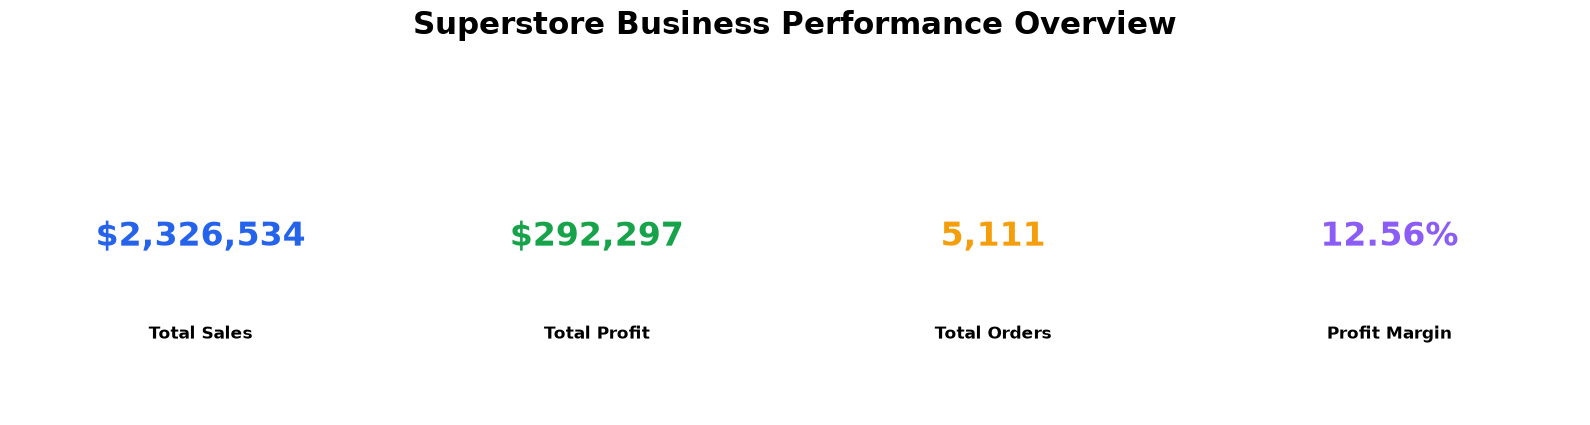

16. KPI performance saved!


In [50]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

kpis = [
    ("Total Sales", f"${total_sales:,.0f}", "#2563EB"),
    ("Total Profit", f"${total_profit:,.0f}", "#16A34A"),
    ("Total Orders", f"{total_orders:,}", "#F59E0B"),
    ("Profit Margin", f"{overall_profit_margin:.2f}%", "#8B5CF6")
]

for ax, (title, value, color) in zip(axes, kpis):

    ax.text(
        0.5,
        0.55,
        value,
        ha="center",
        va="center",
        fontsize=24,
        fontweight="bold",
        color=color
    )

    ax.text(
        0.5,
        0.25,
        title,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "Superstore Business Performance Overview",
    fontsize=22,
    fontweight="bold",
    y=1.05
)

plt.tight_layout()
plt.savefig(
    charts_folder / "business_performance_kpis.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("16. KPI performance saved!")
plt.show()

In [51]:
from pathlib import Path

charts_folder = Path.cwd().parent / "outputs" / "charts"

print("Charts folder:")
print(charts_folder)

print("\nExisting chart files:")
for file in charts_folder.iterdir():
    print(file.name)

Charts folder:
c:\Users\srinu\OneDrive\Desktop\code alpha data visualization\outputs\charts

Existing chart files:
business_performance_kpis.png
correlation_heatmap.png
discount_vs_profit.png
insights
monthly_profit_trend.png
monthly_sales_trend.png
profit_by_category.png
profit_margin_category.png
regional_sales_profit.png
sales_by_category.png
sales_by_segment.png
sales_vs_profit.png
sales_vs_profit_category.png
top_10_profitable_products.png
top_10_subcategories_profit.png
top_10_subcategories_sales.png
yearly_sales_profit.png


In [52]:
print("========== KEY BUSINESS METRICS ==========")

print(f"Total Sales: ${df['Sales'].sum():,.2f}")
print(f"Total Profit: ${df['Profit'].sum():,.2f}")
print(f"Total Orders: {df['Order ID'].nunique():,}")
print(f"Total Customers: {df['Customer ID'].nunique():,}")

profit_margin = (df["Profit"].sum() / df["Sales"].sum()) * 100
print(f"Overall Profit Margin: {profit_margin:.2f}%")

print("\n========== TOP CATEGORY BY SALES ==========")
print(
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

print("\n========== TOP CATEGORY BY PROFIT ==========")
print(
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

print("\n========== TOP SUB-CATEGORY BY SALES ==========")
print(
    df.groupby("Sub-Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

print("\n========== TOP SUB-CATEGORY BY PROFIT ==========")
print(
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

print("\n========== TOP REGION BY SALES ==========")
print(
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

print("\n========== TOP REGION BY PROFIT ==========")
print(
    df.groupby("Region")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

print("\n========== TOP CUSTOMER SEGMENT ==========")
print(
    df.groupby("Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

========== KEY BUSINESS METRICS ==========
Total Sales: $2,326,534.35
Total Profit: $292,296.81
Total Orders: 5,111
Total Customers: 804
Overall Profit Margin: 12.56%

========== TOP CATEGORY BY SALES ==========
Category
Technology    839893.279
Name: Sales, dtype: float64

========== TOP CATEGORY BY PROFIT ==========
Category
Technology    146543.3756
Name: Profit, dtype: float64

========== TOP SUB-CATEGORY BY SALES ==========
Sub-Category
Chairs    335768.249
Name: Sales, dtype: float64

========== TOP SUB-CATEGORY BY PROFIT ==========
Sub-Category
Copiers    56093.9365
Name: Profit, dtype: float64

========== TOP REGION BY SALES ==========
Region
West    739813.6085
Name: Sales, dtype: float64

========== TOP REGION BY PROFIT ==========
Region
West    110798.817
Name: Profit, dtype: float64

========== TOP CUSTOMER SEGMENT ==========
Segment
Consumer    1170659.787
Name: Sales, dtype: float64


In [53]:
print("========== TOP REGION BY SALES ==========")

region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(region_sales)

print("\n========== TOP REGION BY PROFIT ==========")

region_profit = (
    df.groupby("Region")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(region_profit)

print("\n========== PROFIT MARGIN BY CATEGORY ==========")

category_margin = (
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
)

category_margin["Profit Margin (%)"] = (
    category_margin["Profit"] /
    category_margin["Sales"] * 100
)

print(category_margin.sort_values(
    "Profit Margin (%)",
    ascending=False
))

print("\n========== DISCOUNT VS PROFIT ==========")

discount_profit = (
    df.groupby("Discount")["Profit"]
    .sum()
)

print(discount_profit)

========== TOP REGION BY SALES ==========
Region
West       739813.6085
East       691828.1680
Central    503170.6728
South      391721.9050
Name: Sales, dtype: float64

========== TOP REGION BY PROFIT ==========
Region
West       110798.8170
East        94883.2603
South       46749.4303
Central     39865.3070
Name: Profit, dtype: float64

========== PROFIT MARGIN BY CATEGORY ==========
                       Sales       Profit  Profit Margin (%)
Category                                                    
Technology       839893.2790  146543.3756          17.447857
Office Supplies  731893.3140  126023.4434          17.218827
Furniture        754747.7613   19729.9956           2.614118

========== DISCOUNT VS PROFIT ==========
Discount
0.00    326718.5872
0.10      9099.9700
0.15      1418.9915
0.20     91079.9517
0.30    -10513.4456
0.32     -2391.1377
0.40    -23086.3742
0.45     -2493.1111
0.50    -20506.4281
0.60     -6164.3472
0.70    -40300.5727
0.80    -30565.2692
Name: Profit, 

# CodeAlpha Task 3 — Data Visualization

## Superstore Sales & Profit Analysis

This project focuses on analyzing and visualizing business performance
using the Superstore dataset.

The analysis explores sales trends, profitability, product categories,
sub-categories, customer segments, regional performance, discount impact,
and relationships between key business metrics.

### Tools Used

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## 1. Project Setup & Dataset Loading

Load the Superstore dataset and inspect its structure before performing
data preprocessing and visualization.

## 2. Data Preprocessing

Convert date columns into datetime format and create additional
time-based features required for trend analysis.

## 3. Sales & Profit Trends

Analyze monthly sales and profit trends to understand how business
performance changes over time.

## 4. Category Analysis

Compare sales, profit, and profitability across major product
categories.

## 5. Sub-Category Analysis

Identify the highest-performing sub-categories based on sales and
profit.

## 6. Regional & Customer Segment Analysis

Analyze geographic performance and identify the customer segments
that contribute most to overall sales.

## 7. Discount & Profitability Analysis

Examine the relationship between discount levels, profit, and
profit margins to identify potential profitability risks.

## 8. Correlation & Relationship Analysis

Explore relationships between key numerical business metrics such as
sales, quantity, discount, and profit.

## 9. Business Performance Overview

Summarize the key business performance indicators using a KPI-style
visualization.

## 10. Business Insights & Conclusion

The analysis reveals important patterns in sales performance,
profitability, product performance, regional performance, customer
segments, and discount strategy.

Detailed findings and recommendations are documented in:

`outputs/insights/business_insights.md`